# Groupe 2 · Biologie et sciences expérimentales
## Peut-on reconnaître automatiquement une variété de haricot à partir de la forme de ses graines ?

**Données** : UCI Dry Bean, 13 611 graines photographiées, 7 variétés. Pour chaque graine, 16 mesures de forme ont été calculées à partir de l'image (surface, périmètre, longueur, rondeur…).

**Déroulé**
- **Partie A · Explorer les données** (étapes 1 à 9) : statistiques, distributions par variété, valeurs aberrantes, mesures redondantes
- **Partie B · Construire les modèles** (étapes 10 à 13)
- **Partie C · Analyser les résultats** (étapes 14 à 21) : erreurs par variété, réglages, stabilité, effet des valeurs aberrantes
- **Partie D · Utiliser et conclure** (étapes 22 à 24)

*Source : Koklu M., Ozkan I. A. (2020). Multiclass classification of dry beans using computer vision and machine learning techniques. Computers and Electronics in Agriculture, 174 · UCI Machine Learning Repository.*

# Partie A · Explorer les données

## Étape 1 · Installer et importer les outils

In [1]:
# Installe les trois bibliothèques utilisées dans ce notebook (déjà présentes dans Colab : l'installation est alors immédiate).
# Si le message « you may need to restart the kernel » apparaît, on peut l'ignorer.
%pip install -q pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd                      # lire et manipuler des tableaux
import matplotlib.pyplot as plt          # dessiner des graphiques
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold   # séparer les données, validation croisée
from sklearn.preprocessing import StandardScaler              # mettre les mesures à la même échelle
from sklearn.pipeline import make_pipeline                    # enchaîner deux opérations
from sklearn.neighbors import KNeighborsClassifier            # modèle des plus proches voisins
from sklearn.ensemble import RandomForestClassifier           # forêt aléatoire
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

## Étape 2 · Charger les données

In [3]:
import os

# Les fichiers nécessaires : ils doivent être dans le même dossier que ce notebook.
fichiers = ["haricots.csv"]

# Dans Google Colab : si un fichier manque, une fenêtre s'ouvre pour l'envoyer depuis votre ordinateur.
if not all(os.path.exists(f) for f in fichiers):
    from google.colab import files
    files.upload()

donnees = pd.read_csv("haricots.csv")
donnees.head()

,surface,perimetre,grand_axe,petit_axe,allongement,excentricite,surface_convexe,diametre_equivalent,etendue,solidite,rondeur,compacite,facteur_forme_1,facteur_forme_2,facteur_forme_3,facteur_forme_4,variete
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [4]:
print("Nombre de graines :", len(donnees))
print("Mesures par graine :", len(donnees.columns) - 1)

Nombre de graines : 13611
Mesures par graine : 16


**Quelques mesures expliquées**
- `surface`, `perimetre` : en pixels sur la photo ;
- `grand_axe`, `petit_axe` : la plus grande et la plus petite longueur de la graine ;
- `allongement` = grand axe / petit axe (1 = aussi longue que large) ;
- `rondeur` : 1 pour un cercle parfait, plus petit pour une forme irrégulière ;
- `solidite` : surface de la graine / surface de son « enveloppe » convexe (1 = aucune encoche).

## Étape 3 · Statistiques descriptives

In [5]:
donnees.describe().round(3)

,surface,perimetre,grand_axe,petit_axe,allongement,excentricite,surface_convexe,diametre_equivalent,etendue,solidite,rondeur,compacite,facteur_forme_1,facteur_forme_2,facteur_forme_3,facteur_forme_4
count,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000
mean,53048.285,855.283,320.142,202.271,1.583,0.751,53768.200,253.064,0.750,0.987,0.873,0.800,0.007,0.002,0.644,0.995
std,29324.096,214.290,85.694,44.970,0.247,0.092,29774.916,59.177,0.049,0.005,0.060,0.062,0.001,0.001,0.099,0.004
min,20420.000,524.736,183.601,122.513,1.025,0.219,20684.000,161.244,0.555,0.919,0.490,0.641,0.003,0.001,0.410,0.948
25%,36328.000,703.524,253.304,175.848,1.432,0.716,36714.500,215.068,0.719,0.986,0.832,0.762,0.006,0.001,0.581,0.994
50%,44652.000,794.941,296.883,192.432,1.551,0.764,45178.000,238.438,0.760,0.988,0.883,0.801,0.007,0.002,0.642,0.996
75%,61332.000,977.213,376.495,217.032,1.707,0.810,62294.000,279.446,0.787,0.990,0.917,0.834,0.007,0.002,0.696,0.998
max,254616.000,1985.370,738.860,460.198,2.430,0.911,263261.000,569.374,0.866,0.995,0.991,0.987,0.010,0.004,0.975,1.000


**À regarder** : la surface va de 20 000 à plus de 250 000 pixels, alors que la rondeur reste entre 0,49 et 0,99. Les mesures n'ont pas du tout la même échelle : il faudra en tenir compte pour certains modèles.

## Étape 4 · Les valeurs manquantes

In [6]:
print("Valeurs manquantes au total :", donnees.isna().sum().sum())

Valeurs manquantes au total : 0


Aucune valeur manquante : les mesures ont été calculées automatiquement à partir des images.

## Étape 5 · Combien de graines par variété ?

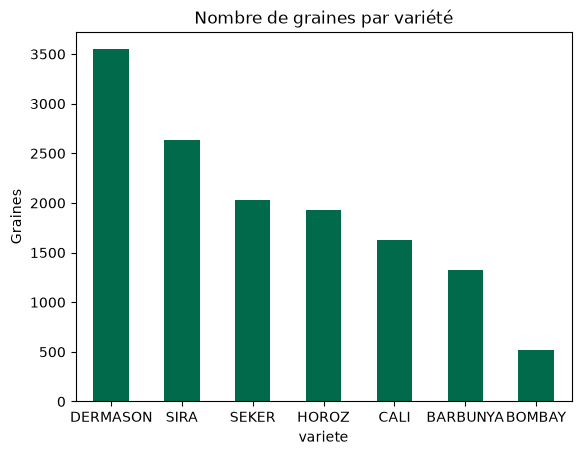

In [7]:
donnees["variete"].value_counts().plot(kind="bar", color="#006A4A", rot=0)
plt.title("Nombre de graines par variété")
plt.ylabel("Graines")
plt.show()

Les variétés ne sont pas équilibrées : près de 3 500 DERMASON, mais à peine plus de 500 BOMBAY. Un modèle aura plus d'exemples pour apprendre certaines variétés que d'autres.

## Étape 6 · Les distributions par variété

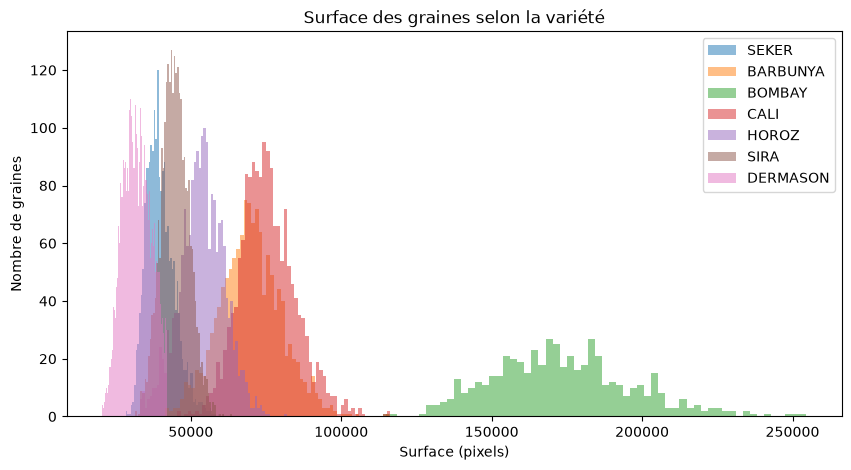

In [8]:
# Histogramme de la surface pour chaque variété
plt.figure(figsize=(10, 5))
for variete in donnees["variete"].unique():
    plt.hist(donnees[donnees["variete"] == variete]["surface"], bins=60, alpha=0.5, label=variete)
plt.title("Surface des graines selon la variété")
plt.xlabel("Surface (pixels)")
plt.ylabel("Nombre de graines")
plt.legend()
plt.show()

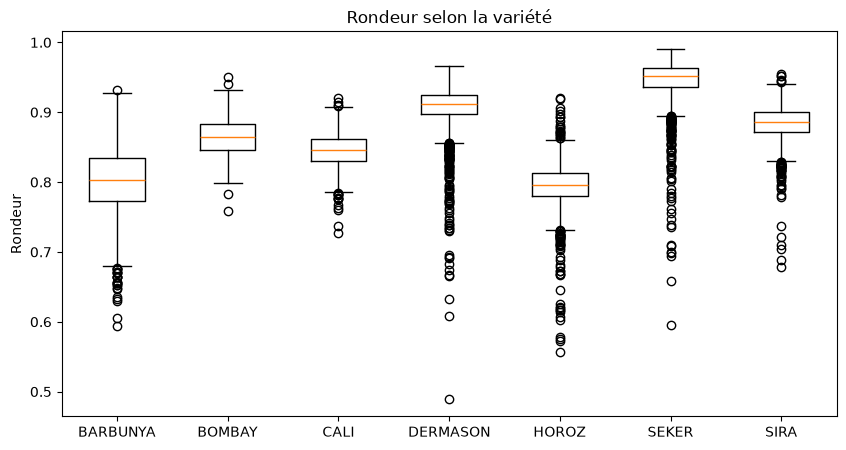

In [9]:
# Boîtes à moustaches de la rondeur, une par variété
varietes = sorted(donnees["variete"].unique())
plt.figure(figsize=(10, 5))
plt.boxplot([donnees[donnees["variete"] == v]["rondeur"] for v in varietes])
plt.xticks(range(1, len(varietes) + 1), varietes)
plt.title("Rondeur selon la variété")
plt.ylabel("Rondeur")
plt.show()

**À regarder** : BOMBAY se distingue tout de suite par sa taille. D'autres variétés (SIRA, DERMASON) ont des distributions très proches : elles seront plus difficiles à séparer.

## Étape 7 · Les valeurs aberrantes

**La règle des quartiles (ou règle de Tukey)**, la plus utilisée pour repérer des valeurs aberrantes :
- Q1 = la valeur sous laquelle se trouvent 25 % des observations ; Q3 = celle sous laquelle se trouvent 75 % ;
- l'écart interquartile vaut Q3 − Q1 ;
- une valeur est dite **aberrante** si elle est en dessous de Q1 − 1,5 × écart ou au-dessus de Q3 + 1,5 × écart.

Attention : *aberrant* veut dire *inhabituel*, pas forcément *faux*. Chaque valeur repérée se discute avec la connaissance du terrain.

In [10]:
q1 = donnees["rondeur"].quantile(0.25)
q3 = donnees["rondeur"].quantile(0.75)
ecart = q3 - q1
limite_basse = q1 - 1.5 * ecart

print("Q1 =", round(q1, 3), "  Q3 =", round(q3, 3), "  limite basse =", round(limite_basse, 3))

peu_rondes = donnees[donnees["rondeur"] < limite_basse]
print("Graines anormalement peu rondes :", len(peu_rondes))
peu_rondes["variete"].value_counts()

Q1 = 0.832   Q3 = 0.917   limite basse = 0.705
Graines anormalement peu rondes : 91


variete
BARBUNYA    50
HOROZ       23
DERMASON    10
SEKER        5
SIRA         3
Name: count, dtype: int64

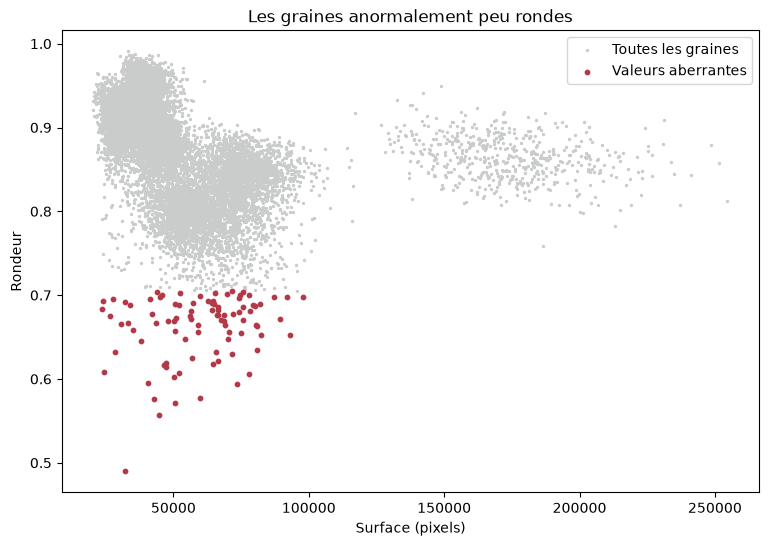

In [11]:
# Où sont ces graines sur le graphique ?
plt.figure(figsize=(9, 6))
plt.scatter(donnees["surface"], donnees["rondeur"], s=2, color="#C9CCCA", label="Toutes les graines")
plt.scatter(peu_rondes["surface"], peu_rondes["rondeur"], s=10, color="#B23A48", label="Valeurs aberrantes")
plt.xlabel("Surface (pixels)")
plt.ylabel("Rondeur")
plt.title("Les graines anormalement peu rondes")
plt.legend()
plt.show()

**À discuter** : ces graines sont-elles des graines cassées, deux graines collées sur la photo, ou une erreur de détection du contour ? Sans revoir les images, on ne peut pas trancher.
Pour l'instant, on les **garde**. À l'étape 20, on mesurera ce que change leur retrait.

## Étape 8 · Les liens entre mesures : les corrélations

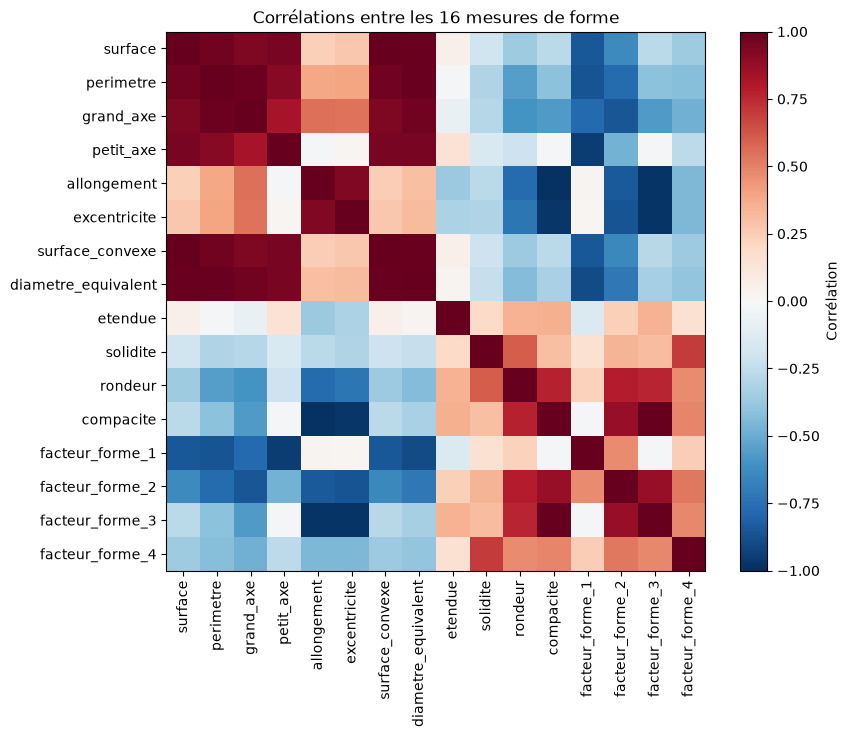

In [12]:
correlations = donnees[list(donnees.columns.drop("variete"))].corr()      # corrélation entre chaque paire de colonnes (de -1 à 1)

plt.figure(figsize=(9, 7))
plt.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)    # rouge = varient ensemble, bleu = en sens contraire
plt.colorbar(label="Corrélation")
plt.xticks(range(len(correlations)), correlations.columns, rotation=90)
plt.yticks(range(len(correlations)), correlations.columns)
plt.title("Corrélations entre les 16 mesures de forme")
plt.show()

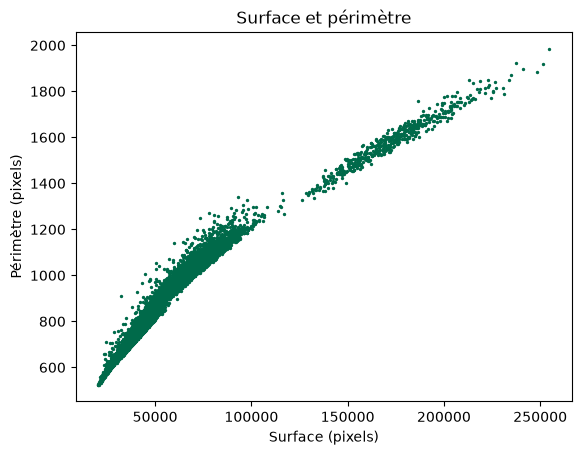

Corrélation surface / périmètre : 0.967


In [13]:
# Deux mesures presque identiques : la surface et le périmètre
plt.scatter(donnees["surface"], donnees["perimetre"], s=2, color="#006A4A")
plt.xlabel("Surface (pixels)")
plt.ylabel("Périmètre (pixels)")
plt.title("Surface et périmètre")
plt.show()

print("Corrélation surface / périmètre :", round(donnees["surface"].corr(donnees["perimetre"]), 3))

Plusieurs mesures disent presque la même chose (surface, périmètre, surface convexe, diamètre équivalent). Elles sont **redondantes** : on le vérifiera à l'étape 19 en n'en gardant que deux.

## Étape 9 · Visualiser les variétés sur deux mesures

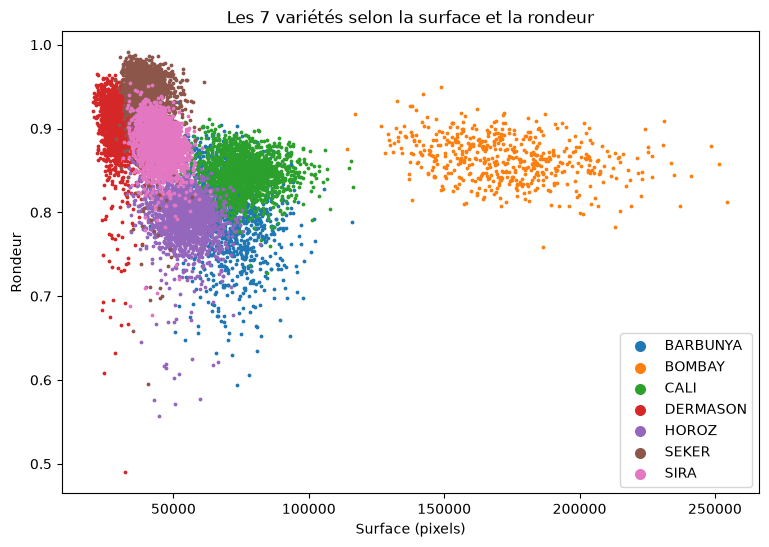

In [14]:
plt.figure(figsize=(9, 6))
for variete in varietes:
    graines = donnees[donnees["variete"] == variete]
    plt.scatter(graines["surface"], graines["rondeur"], s=3, label=variete)
plt.xlabel("Surface (pixels)")
plt.ylabel("Rondeur")
plt.title("Les 7 variétés selon la surface et la rondeur")
plt.legend(markerscale=4)
plt.show()

# Partie B · Construire les modèles

## Étape 10 · Préparer les données

In [15]:
X = donnees.drop(columns="variete")   # les 16 mesures de forme
y = donnees["variete"]                # la variété à reconnaître

## Étape 11 · Séparer apprentissage et test

On cache 30 % des graines au modèle pour vérifier ensuite s'il reconnaît des graines qu'il n'a jamais vues.

In [16]:
X_apprentissage, X_test, y_apprentissage, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

print("Graines pour apprendre :", len(X_apprentissage))
print("Graines pour tester :", len(X_test))

Graines pour apprendre :

 9527
Graines pour tester : 4084


## Étape 12 · Premier modèle : les plus proches voisins (KNN)

Pour une nouvelle graine, le modèle cherche les 7 graines les plus ressemblantes parmi celles qu'il connaît, et choisit la variété la plus fréquente parmi elles.
Comme les mesures n'ont pas la même échelle, on les remet d'abord à la même échelle (`StandardScaler`).

In [17]:
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))
knn.fit(X_apprentissage, y_apprentissage)

predictions_knn = knn.predict(X_test)
print("Bonnes réponses (KNN) :", round(accuracy_score(y_test, predictions_knn) * 100, 1), "%")

Bonnes réponses (KNN) : 91.7 %


## Étape 13 · Modèle d'IA : la forêt aléatoire

In [18]:
foret = RandomForestClassifier(n_estimators=300, random_state=42)
foret.fit(X_apprentissage, y_apprentissage)

predictions_foret = foret.predict(X_test)
print("Bonnes réponses (forêt aléatoire) :", round(accuracy_score(y_test, predictions_foret) * 100, 1), "%")

Bonnes réponses (forêt aléatoire) : 92.0 %


# Partie C · Analyser les résultats

## Étape 14 · Le tableau des confusions

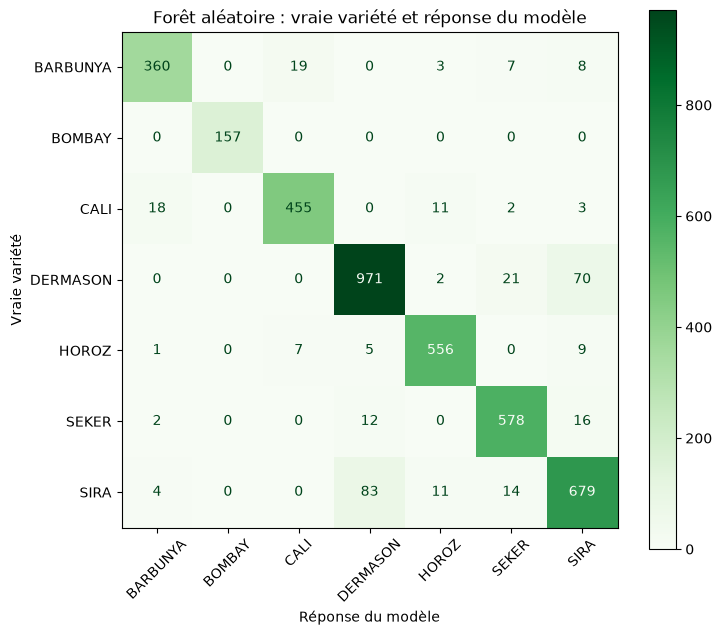

In [19]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, predictions_foret, cmap="Greens", ax=ax, xticks_rotation=45)
plt.title("Forêt aléatoire : vraie variété et réponse du modèle")
plt.xlabel("Réponse du modèle")
plt.ylabel("Vraie variété")
plt.show()

## Étape 15 · La réussite variété par variété

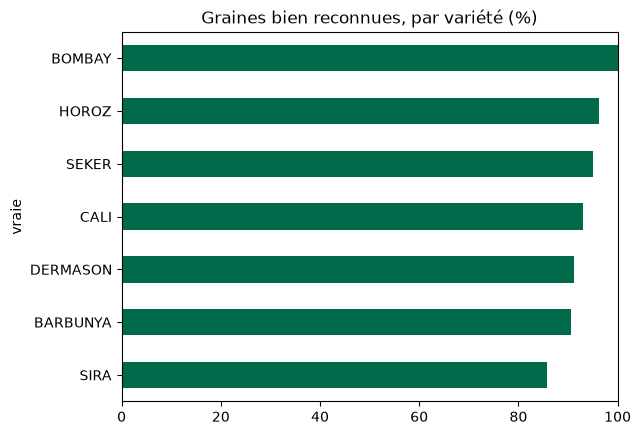

vraie
SIRA         85.8
BARBUNYA     90.7
DERMASON     91.3
CALI         93.0
SEKER        95.1
HOROZ        96.2
BOMBAY      100.0
Name: correct, dtype: float64

In [20]:
resultats = pd.DataFrame({"vraie": y_test, "predite": predictions_foret})
resultats["correct"] = resultats["vraie"] == resultats["predite"]

reussite = resultats.groupby("vraie")["correct"].mean().sort_values() * 100
reussite.plot(kind="barh", color="#006A4A")
plt.title("Graines bien reconnues, par variété (%)")
plt.xlim(0, 100)
plt.show()
reussite.round(1)

## Étape 16 · Où sont les erreurs ?

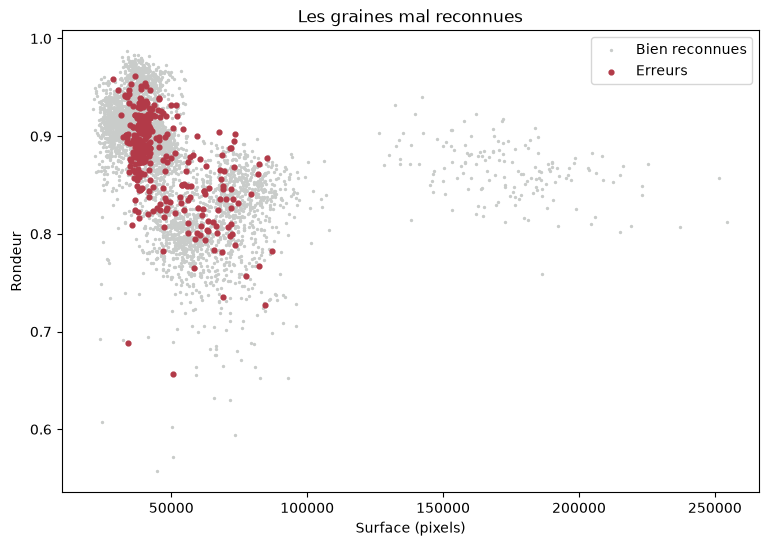

Nombre d'erreurs : 328 sur 4084


In [21]:
erreurs = X_test[predictions_foret != y_test]

plt.figure(figsize=(9, 6))
plt.scatter(X_test["surface"], X_test["rondeur"], s=2, color="#C9CCCA", label="Bien reconnues")
plt.scatter(erreurs["surface"], erreurs["rondeur"], s=12, color="#B23A48", label="Erreurs")
plt.xlabel("Surface (pixels)")
plt.ylabel("Rondeur")
plt.title("Les graines mal reconnues")
plt.legend()
plt.show()

print("Nombre d'erreurs :", len(erreurs), "sur", len(X_test))

**À discuter** : les erreurs se concentrent là où les nuages de variétés se chevauchent (étape 9). Le modèle se trompe là où un œil humain hésiterait aussi.

## Étape 17 · Le réglage du KNN : combien de voisins ?

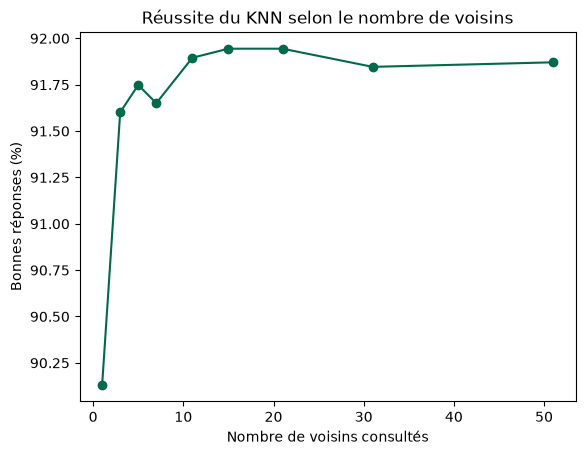

In [22]:
nombres_de_voisins = [1, 3, 5, 7, 11, 15, 21, 31, 51]
scores = []
for k in nombres_de_voisins:
    essai = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    essai.fit(X_apprentissage, y_apprentissage)
    scores.append(accuracy_score(y_test, essai.predict(X_test)) * 100)

plt.plot(nombres_de_voisins, scores, marker="o", color="#006A4A")
plt.title("Réussite du KNN selon le nombre de voisins")
plt.xlabel("Nombre de voisins consultés")
plt.ylabel("Bonnes réponses (%)")
plt.show()

Avec 1 seul voisin, le modèle copie la graine la plus proche, même si c'est une exception. Avec trop de voisins, il mélange des variétés différentes. Le meilleur réglage est entre les deux.

## Étape 18 · Le surapprentissage : la profondeur des arbres

In [23]:
for profondeur in [2, 4, 8, 16, None]:
    essai = RandomForestClassifier(n_estimators=200, max_depth=profondeur, random_state=42)
    essai.fit(X_apprentissage, y_apprentissage)
    sur_apprentissage = accuracy_score(y_apprentissage, essai.predict(X_apprentissage))
    sur_test = accuracy_score(y_test, essai.predict(X_test))
    print("Profondeur", profondeur, "| apprentissage :", round(sur_apprentissage * 100, 1), "%", "| test :", round(sur_test * 100, 1), "%")

Profondeur 2 | apprentissage : 77.8 % | test : 77.2 %


Profondeur 4 | apprentissage : 88.9 % | test : 88.3 %


Profondeur 8 | apprentissage : 94.3 % | test : 91.7 %


Profondeur 16 | apprentissage : 99.7 % | test : 92.1 %


Profondeur None | apprentissage : 100.0 % | test : 92.0 %


Sans limite de profondeur (`None`), les arbres reconnaissent presque 100 % des graines qu'ils ont vues, mais pas davantage de graines nouvelles : ils ont appris par cœur. **Seul le score sur le test compte.**

## Étape 19 · Faut-il vraiment 16 mesures ?

In [24]:
deux_mesures = ["surface", "rondeur"]
foret_deux = RandomForestClassifier(n_estimators=300, random_state=42)
foret_deux.fit(X_apprentissage[deux_mesures], y_apprentissage)

print("Avec 16 mesures :", round(accuracy_score(y_test, predictions_foret) * 100, 1), "%")
print("Avec 2 mesures (surface, rondeur) :", round(accuracy_score(y_test, foret_deux.predict(X_test[deux_mesures])) * 100, 1), "%")

Avec 16 mesures : 92.0 %
Avec 2 mesures (surface, rondeur) : 81.0 %


## Étape 20 · L'effet des valeurs aberrantes

Retirons les graines anormalement peu rondes (étape 7) et refaisons tout.

In [25]:
sans_aberrantes = donnees[donnees["rondeur"] >= limite_basse]
print("Graines conservées :", len(sans_aberrantes), "sur", len(donnees))

Xs = sans_aberrantes.drop(columns="variete")
ys = sans_aberrantes["variete"]
Xs_app, Xs_test, ys_app, ys_test = train_test_split(Xs, ys, test_size=0.3, stratify=ys, random_state=42)

foret_sans = RandomForestClassifier(n_estimators=300, random_state=42)
foret_sans.fit(Xs_app, ys_app)
print("Avec les valeurs aberrantes :", round(accuracy_score(y_test, predictions_foret) * 100, 1), "%")
print("Sans les valeurs aberrantes :", round(accuracy_score(ys_test, foret_sans.predict(Xs_test)) * 100, 1), "%")

Graines conservées : 13520 sur 13611


Avec les valeurs aberrantes : 92.0 %
Sans les valeurs aberrantes : 92.4 %


**À discuter** : le score change peu. Mais attention : en retirant les graines difficiles, on facilite aussi le test. Un score qui monte après un nettoyage n'est pas forcément un meilleur modèle.

## Étape 21 · La stabilité du résultat : la validation croisée

In [26]:
# 5 parts, en mélangeant d'abord les graines (shuffle=True)
decoupage = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores_knn = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)), X, y, cv=decoupage)
scores_foret = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=42), X, y, cv=decoupage)

print("KNN, 5 essais :", (scores_knn * 100).round(1), "→ moyenne", round(scores_knn.mean() * 100, 1), "%")
print("Forêt, 5 essais :", (scores_foret * 100).round(1), "→ moyenne", round(scores_foret.mean() * 100, 1), "%")

KNN, 5 essais : [91.6 92.7 92.2 92.9 92.5] → moyenne 92.4 %
Forêt, 5 essais : [91.7 92.8 92.7 93.1 92.2] → moyenne 92.5 %


Les 5 essais donnent des scores très proches : le résultat est stable.

**Le piège à éviter** : dans le fichier, les graines sont rangées variété par variété. Si on découpe en 5 parts **sans mélanger**, chaque part contient surtout certaines variétés, que le modèle a peu vues pendant l'apprentissage.

In [27]:
sans_melange = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=42), X, y, cv=5)    # cv=5 : 5 parts dans l'ordre du fichier
print("Forêt, 5 parts sans mélanger :", (sans_melange * 100).round(1), "→ moyenne", round(sans_melange.mean() * 100, 1), "%")

Forêt, 5 parts sans mélanger : [49.  75.1 80.8 67.6 32.6] → moyenne 61.0 %


Les scores s'effondrent et varient énormément : ce n'est pas le modèle qui est mauvais, c'est le test qui est mal construit. **Regardez toujours dans quel ordre sont rangées vos données.**

# Partie D · Utiliser et conclure

## Étape 22 · Ce qui compte pour le modèle

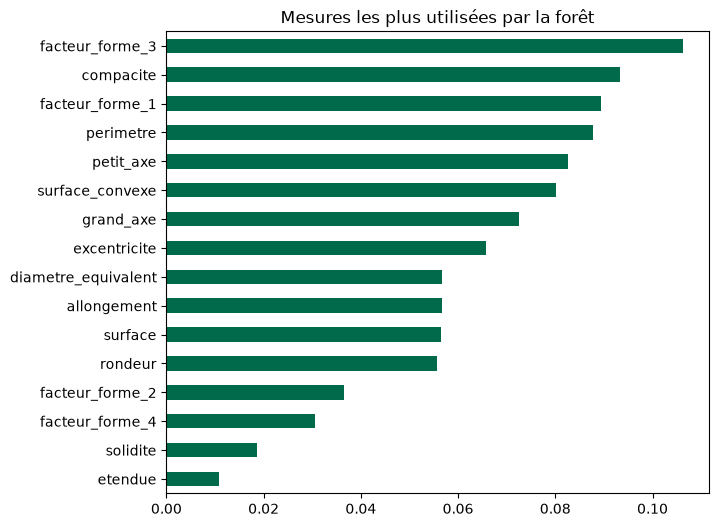

In [28]:
importance = pd.Series(foret.feature_importances_, index=X.columns).sort_values()

importance.plot(kind="barh", color="#006A4A", figsize=(7, 6))
plt.title("Mesures les plus utilisées par la forêt")
plt.show()

## Étape 23 · Reconnaître une nouvelle graine

In [29]:
nouvelle_graine = X_test.iloc[[0]]          # les mesures d'une graine du test, comme si elle venait d'être photographiée
print("Réponse du modèle :", foret.predict(nouvelle_graine)[0])
print("Vraie variété :", y_test.iloc[0])

pd.Series(foret.predict_proba(nouvelle_graine)[0], index=foret.classes_).round(2).sort_values(ascending=False)

Réponse du modèle : SEKER
Vraie variété : SEKER


SEKER       1.0
BOMBAY      0.0
BARBUNYA    0.0
CALI        0.0
DERMASON    0.0
HOROZ       0.0
SIRA        0.0
dtype: float64